In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("../results/timings.csv")
e1 = df[(df.experiment == "E1_build_memory") & (df.machine_id == "vivian-mbp")].copy()
print(e1.code_version.unique())
e1 = e1[e1.code_version == "NEW_HASH"]
e1["ns_per_key"] = e1.total_ns / e1.n_ops
print(e1.groupby(["index_type", "n_keys"]).ns_per_key.median().unstack(0))

<StringArray>
['af79e03', '3c5068c']
Length: 2, dtype: str
Empty DataFrame
Columns: []
Index: []


Empty DataFrame
Columns: [index, slope]
Index: []


/tmp/ipykernel_18/2205806980.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.set_xlabel("n"); ax.set_ylabel("build time (ns)"); ax.legend()


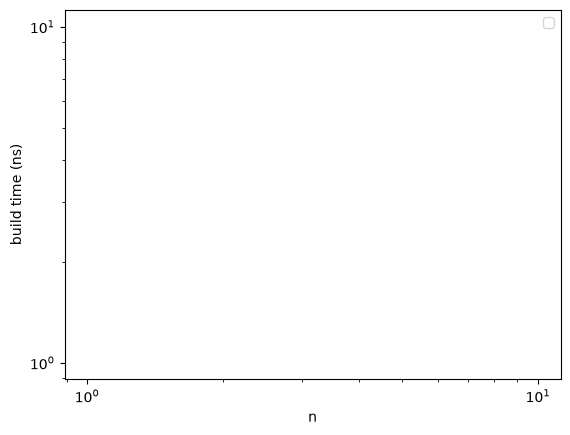

Series([], Name: memory_bytes, dtype: float64)


In [4]:
# log-log slope of total build time vs n, per index
rows = []
for name, g in e1.groupby("index_type"):
    med = g.groupby("n_keys").total_ns.median()
    slope = np.polyfit(np.log(med.index), np.log(med.values), 1)[0]
    rows.append((name, round(slope, 2)))
print(pd.DataFrame(rows, columns=["index", "slope"]))

# median with IQR band, log-log
fig, ax = plt.subplots()
for name, g in e1.groupby("index_type"):
    s = g.groupby("n_keys").total_ns
    med, q1, q3 = s.median(), s.quantile(.25), s.quantile(.75)
    ax.plot(med.index, med.values, marker="o", label=name)
    ax.fill_between(med.index, q1.values, q3.values, alpha=.2)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("n"); ax.set_ylabel("build time (ns)"); ax.legend()
plt.show()

# memory per key at the largest n
big = e1[e1.n_keys == 114000]
print((big.groupby("index_type").memory_bytes.median() / 114000).round(1))